In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
# Load the dataset
# Load the dataset
df = pd.read_csv("../data/student-mat.csv", sep=";")

# Display the first 5 rows
df.head()

# Display the first 5 rows
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [6]:
# Check the dataset structure
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [7]:
# Create a binary target variable
# Pass = final grade of 10 or above
# Fail = final grade below 10

df["pass"] = (df["G3"] >= 10).astype(int)

# Check the number of passing and failing students
print(df["pass"].value_counts())

pass
1    265
0    130
Name: count, dtype: int64


In [8]:
# Select the input features
features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

X = df[features]
y = df["pass"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 316
Testing samples: 79


In [15]:
# Train the Logistic Regression model

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train, y_train)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test)

# Calculate accuracy
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.8734177215189873


In [16]:
# Train the Decision Tree model

tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(X_train, y_train)

# Make predictions
y_pred_tree = tree_model.predict(X_test)

# Calculate accuracy
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 0.8860759493670886


In [17]:
# Compare model performance

print("Model Performance Comparison")
print("--------------------------------")
print("Logistic Regression Accuracy:", logistic_accuracy)
print("Decision Tree Accuracy:", tree_accuracy)

if logistic_accuracy > tree_accuracy:
    print("\nLogistic Regression performed better.")
elif tree_accuracy > logistic_accuracy:
    print("\nDecision Tree performed better.")
else:
    print("\nBoth models performed equally.")

Model Performance Comparison
--------------------------------
Logistic Regression Accuracy: 0.8734177215189873
Decision Tree Accuracy: 0.8860759493670886

Decision Tree performed better.


In [20]:
# Evaluate Logistic Regression

print("LOGISTIC REGRESSION")
print("-------------------")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))

LOGISTIC REGRESSION
-------------------
Confusion Matrix:
[[23  3]
 [ 7 46]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.88      0.82        26
           1       0.94      0.87      0.90        53

    accuracy                           0.87        79
   macro avg       0.85      0.88      0.86        79
weighted avg       0.88      0.87      0.88        79



In [21]:
print("DECISION TREE")
print("----------------")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

DECISION TREE
----------------
Confusion Matrix:
[[24  2]
 [ 7 46]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.92      0.84        26
           1       0.96      0.87      0.91        53

    accuracy                           0.89        79
   macro avg       0.87      0.90      0.88        79
weighted avg       0.90      0.89      0.89        79



In [23]:
# Compare model accuracy

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [logistic_accuracy, tree_accuracy]
})

print(results)

                 Model  Accuracy
0  Logistic Regression  0.873418
1        Decision Tree  0.886076


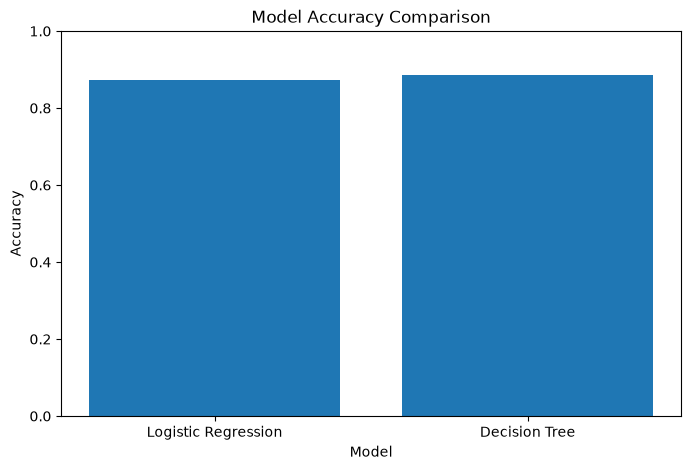

In [24]:
# Visual comparison of model accuracy

plt.figure(figsize=(8, 5))

plt.bar(results["Model"], results["Accuracy"])

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()

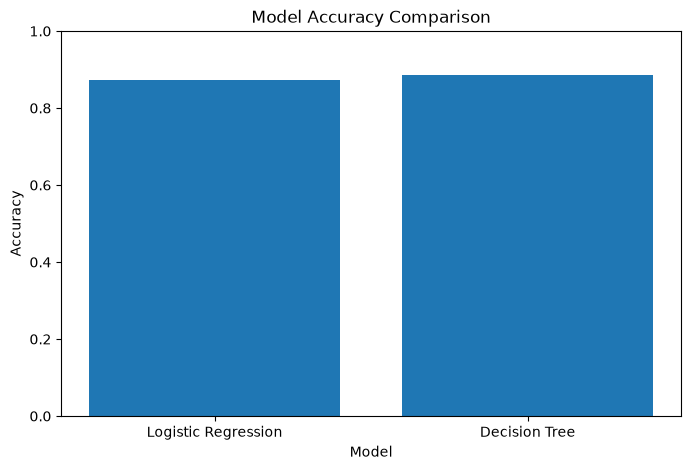

In [25]:
# Save the model accuracy chart

plt.figure(figsize=(8, 5))

plt.bar(results["Model"], results["Accuracy"])

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.savefig("../results/model_accuracy_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

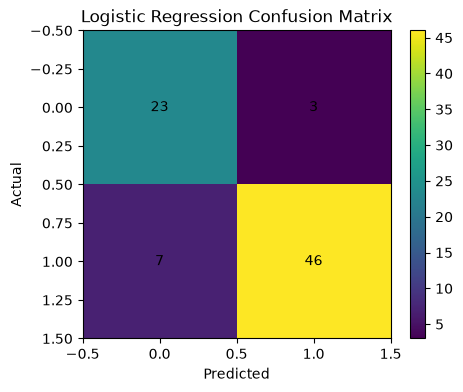

In [26]:
# Logistic Regression confusion matrix

cm_logistic = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(5, 4))
plt.imshow(cm_logistic)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

for i in range(cm_logistic.shape[0]):
    for j in range(cm_logistic.shape[1]):
        plt.text(j, i, cm_logistic[i, j], ha="center", va="center")

plt.savefig("../results/logistic_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

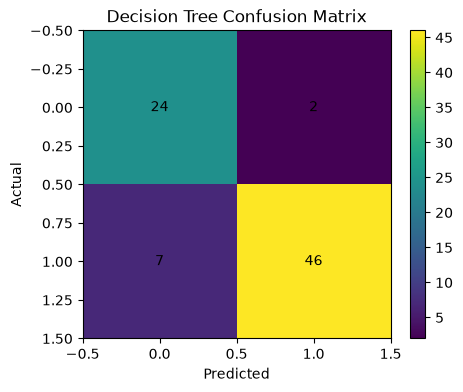

In [27]:
# Decision Tree confusion matrix

cm_tree = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(5, 4))
plt.imshow(cm_tree)
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

for i in range(cm_tree.shape[0]):
    for j in range(cm_tree.shape[1]):
        plt.text(j, i, cm_tree[i, j], ha="center", va="center")

plt.savefig("../results/decision_tree_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [28]:
# Model comparison summary

if tree_accuracy > logistic_accuracy:
    print("The Decision Tree performed better than Logistic Regression based on accuracy.")
elif logistic_accuracy > tree_accuracy:
    print("Logistic Regression performed better than the Decision Tree based on accuracy.")
else:
    print("Both models achieved the same accuracy.")

print("\nDecision Tree Accuracy:", tree_accuracy)
print("Logistic Regression Accuracy:", logistic_accuracy)

The Decision Tree performed better than Logistic Regression based on accuracy.

Decision Tree Accuracy: 0.8860759493670886
Logistic Regression Accuracy: 0.8734177215189873
